<center><h1>Liu_Peiyi_HW5</h1></center>
<br>
<br>

Name: Peiyi Liu
<br>
Github Username: Eternal-799
<br>
USC ID: 2086699860 

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import (StratifiedKFold, KFold, cross_val_score,
                                     GridSearchCV)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
RANDOM_STATE = 42

### (a) Obtain Data

Get the Acute Inflammations Data Set

In [2]:
ACUTE_PATH = "../data/diagnosis.data"

acute_cols = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
              "micturition_pains", "burning_urethra",
              "bladder_inflammation", "nephritis"]

def read_acute(path):
    # The original file is UTF-16; fall back to other encodings just in case.
    for enc in ("utf-16", "utf-8", "latin-1"):
        try:
            df = pd.read_csv(path, sep=r"\s+", header=None, names=acute_cols,
                             encoding=enc, decimal=",", engine="python")
            if df.shape[1] == 8 and df["temperature"].dtype != object:
                return df
        except (UnicodeError, ValueError):
            continue
    raise ValueError("Could not parse " + path)

acute = read_acute(ACUTE_PATH)
binary_cols = acute_cols[1:]
acute[binary_cols] = (acute[binary_cols]
                      .apply(lambda s: s.str.strip().str.lower())
                      .replace({"yes": 1, "no": 0})
                      .astype(int))
print("Shape:", acute.shape)
acute.head()

Shape: (120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

This is a **multi-label** data set (two binary labels per patient). Following the footnote, I use the **label powerset** method:
each distinct combination of `(bladder_inflammation, nephritis)` becomes one class, so the problem becomes a 4-class problem.

*Is label powerset more relevant here than binary relevance?* Yes, for three reasons:
- Binary relevance builds one independent tree per label and ignores the dependency between the two diseases. Label powerset models the joint outcome directly, so a patient can have none, either, or both.
- There are only 2 labels, so there are at most $2^2 = 4$ classes and no class explosion.
- A single tree gives one compact, interpretable set of rules for the whole diagnosis.

For comparison I also fit sklearn's native multi-output tree.

Class distribution (label powerset):
bladder_only      40
nephritis_only    31
none              30
both              19
Name: count, dtype: int64 

Training accuracy: 1.0
Depth: 4  Leaves: 6


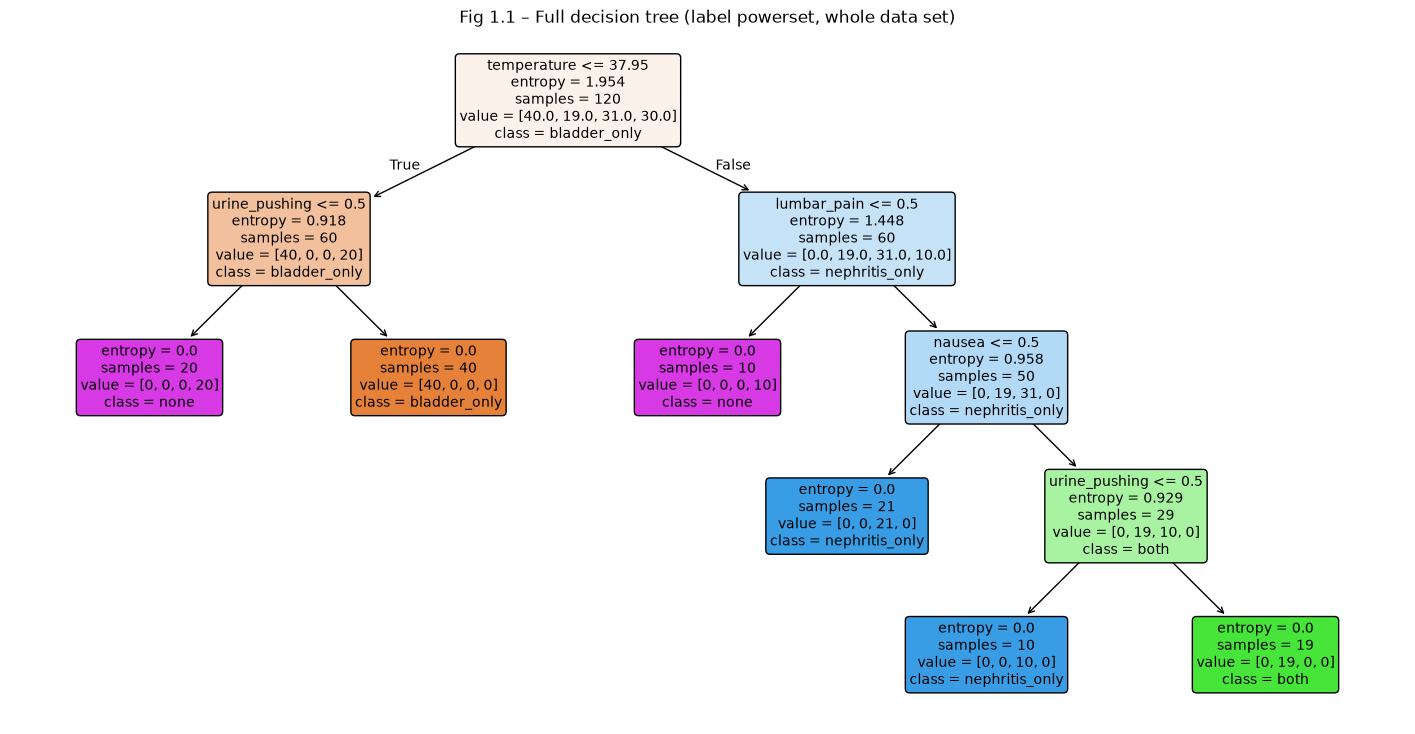

In [3]:
X_acute = acute[acute_cols[:6]]
Y_acute = acute[["bladder_inflammation", "nephritis"]]

# Label powerset: combine the two labels into one class
label_map = {(0, 0): "none", (1, 0): "bladder_only",
             (0, 1): "nephritis_only", (1, 1): "both"}
y_lp = Y_acute.apply(lambda r: label_map[(r.iloc[0], r.iloc[1])], axis=1)
print("Class distribution (label powerset):")
print(y_lp.value_counts(), "\n")

tree_full = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE)
tree_full.fit(X_acute, y_lp)
print("Training accuracy:", tree_full.score(X_acute, y_lp))
print("Depth:", tree_full.get_depth(), " Leaves:", tree_full.get_n_leaves())

plt.figure(figsize=(18, 9))
plot_tree(tree_full, feature_names=X_acute.columns, class_names=tree_full.classes_,
          filled=True, rounded=True, fontsize=10)
plt.title("Fig 1.1 – Full decision tree (label powerset, whole data set)")
plt.show()

In [4]:
# For comparison: sklearn's native multi-label (multi-output) tree
tree_mo = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE)
tree_mo.fit(X_acute, Y_acute)
print("Multi-output tree – depth:", tree_mo.get_depth(),
      " leaves:", tree_mo.get_n_leaves(),
      " exact-match training accuracy:",
      (tree_mo.predict(X_acute) == Y_acute.values).all(axis=1).mean())

Multi-output tree – depth: 4  leaves: 6  exact-match training accuracy: 1.0


### (c) Convert the decision rules

The rules are extracted by walking every root-to-leaf path of the fitted tree (adapted from the KDnuggets code referenced in the homework).
Each leaf becomes one `IF <conjunction of conditions> THEN <class>` rule. Binary features are printed as `= yes / = no` for readability.

In [5]:
def tree_to_rules(clf, feature_names, binary_features=()):
    """Return a list of IF-THEN rules (strings) for a fitted DecisionTreeClassifier."""
    t = clf.tree_
    rules = []

    def cond_text(feat, thr, left):
        if feat in binary_features:            # 0/1 feature split at 0.5
            return f"{feat} = {'no' if left else 'yes'}"
        return f"{feat} <= {thr:.2f}" if left else f"{feat} > {thr:.2f}"

    def recurse(node, conds):
        if t.children_left[node] == t.children_right[node]:      # leaf
            counts = t.value[node][0]
            cls = clf.classes_[np.argmax(counts)]
            n = int(t.n_node_samples[node])
            rule = "IF " + (" AND ".join(conds) if conds else "TRUE")
            rules.append(f"{rule} THEN diagnosis = {cls}   (samples = {n})")
            return
        feat = feature_names[t.feature[node]]
        thr = t.threshold[node]
        recurse(t.children_left[node], conds + [cond_text(feat, thr, True)])
        recurse(t.children_right[node], conds + [cond_text(feat, thr, False)])

    recurse(0, [])
    return rules

rules_full = tree_to_rules(tree_full, list(X_acute.columns), binary_features=set(binary_cols))
for i, r in enumerate(rules_full, 1):
    print(f"Rule {i}: {r}")

Rule 1: IF temperature <= 37.95 AND urine_pushing = no THEN diagnosis = none   (samples = 20)
Rule 2: IF temperature <= 37.95 AND urine_pushing = yes THEN diagnosis = bladder_only   (samples = 40)
Rule 3: IF temperature > 37.95 AND lumbar_pain = no THEN diagnosis = none   (samples = 10)
Rule 4: IF temperature > 37.95 AND lumbar_pain = yes AND nausea = no THEN diagnosis = nephritis_only   (samples = 21)
Rule 5: IF temperature > 37.95 AND lumbar_pain = yes AND nausea = yes AND urine_pushing = no THEN diagnosis = nephritis_only   (samples = 10)
Rule 6: IF temperature > 37.95 AND lumbar_pain = yes AND nausea = yes AND urine_pushing = yes THEN diagnosis = both   (samples = 19)


Class meaning:
- `none`: neither disease
- `bladder_only`: inflammation of urinary bladder only
- `nephritis_only`: nephritis of renal pelvis origin only
- `both`: both diseases

The same rules in sklearn's text format:

In [6]:
print(export_text(tree_full, feature_names=list(X_acute.columns)))

|--- temperature <= 37.95
|   |--- urine_pushing <= 0.50
|   |   |--- class: none
|   |--- urine_pushing >  0.50
|   |   |--- class: bladder_only
|--- temperature >  37.95
|   |--- lumbar_pain <= 0.50
|   |   |--- class: none
|   |--- lumbar_pain >  0.50
|   |   |--- nausea <= 0.50
|   |   |   |--- class: nephritis_only
|   |   |--- nausea >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: nephritis_only
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: both



### (d) Cost-complexity pruning

I compute the cost-complexity pruning path ($\alpha_{\text{eff}}$ values) and evaluate each $\alpha$ with 5-fold stratified cross-validation.
I then choose the **largest** $\alpha$ whose CV accuracy equals the best CV accuracy. That $\alpha$ gives the smallest tree with no loss in CV accuracy, i.e. a minimal, highly interpretable tree.

,ccp_alpha,cv_accuracy,n_leaves
0,0.000000,1.000000,6
1,0.199592,0.866667,4
2,0.325011,0.766667,3
3,0.459148,0.633333,2
4,0.770426,0.433333,1


Chosen ccp_alpha = 0.0000  (CV accuracy = 1.0000)


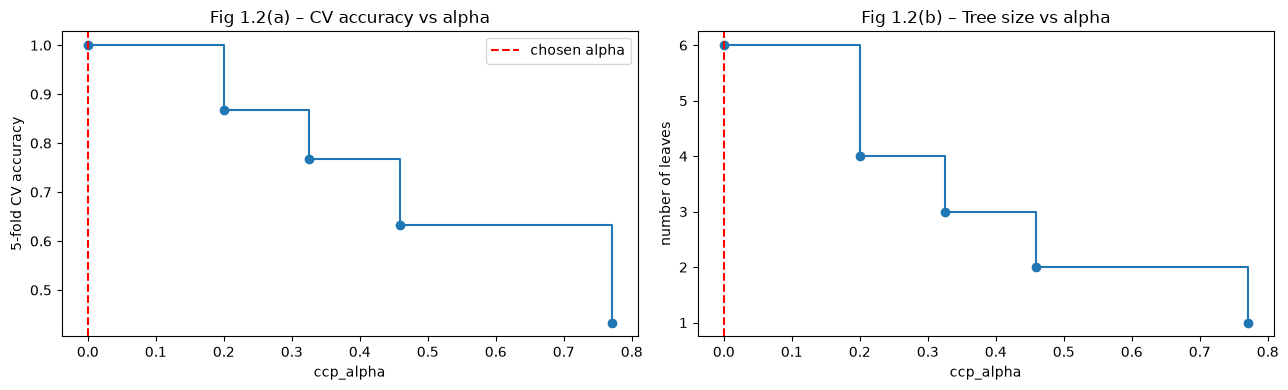

In [7]:
path = tree_full.cost_complexity_pruning_path(X_acute, y_lp)
ccp_alphas = np.unique(path.ccp_alphas)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_acc, n_leaves = [], []
for a in ccp_alphas:
    clf = DecisionTreeClassifier(criterion="entropy", ccp_alpha=a, random_state=RANDOM_STATE)
    cv_acc.append(cross_val_score(clf, X_acute, y_lp, cv=cv).mean())
    n_leaves.append(clf.fit(X_acute, y_lp).get_n_leaves())
cv_acc = np.array(cv_acc)

prune_table = pd.DataFrame({"ccp_alpha": ccp_alphas, "cv_accuracy": cv_acc, "n_leaves": n_leaves})
display(prune_table)

best_alpha = ccp_alphas[np.where(np.isclose(cv_acc, cv_acc.max()))[0].max()]
print(f"Chosen ccp_alpha = {best_alpha:.4f}  (CV accuracy = {cv_acc.max():.4f})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ccp_alphas, cv_acc, marker="o", drawstyle="steps-post")
ax[0].axvline(best_alpha, color="r", ls="--", label="chosen alpha")
ax[0].set(xlabel="ccp_alpha", ylabel="5-fold CV accuracy", title="Fig 1.2(a) – CV accuracy vs alpha")
ax[0].legend()
ax[1].plot(ccp_alphas, n_leaves, marker="o", drawstyle="steps-post")
ax[1].axvline(best_alpha, color="r", ls="--")
ax[1].set(xlabel="ccp_alpha", ylabel="number of leaves", title="Fig 1.2(b) – Tree size vs alpha")
plt.tight_layout()
plt.show()

Pruned tree – depth: 4  leaves: 6  training accuracy: 1.0


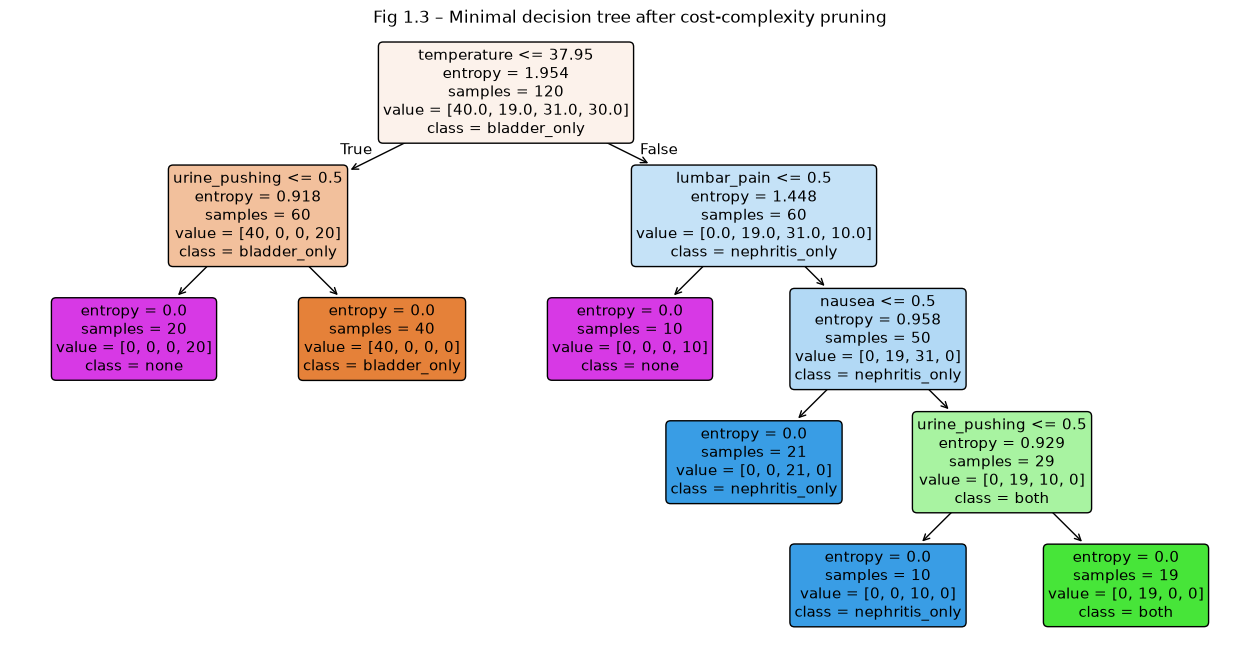

Decision rules of the pruned tree:
Rule 1: IF temperature <= 37.95 AND urine_pushing = no THEN diagnosis = none   (samples = 20)
Rule 2: IF temperature <= 37.95 AND urine_pushing = yes THEN diagnosis = bladder_only   (samples = 40)
Rule 3: IF temperature > 37.95 AND lumbar_pain = no THEN diagnosis = none   (samples = 10)
Rule 4: IF temperature > 37.95 AND lumbar_pain = yes AND nausea = no THEN diagnosis = nephritis_only   (samples = 21)
Rule 5: IF temperature > 37.95 AND lumbar_pain = yes AND nausea = yes AND urine_pushing = no THEN diagnosis = nephritis_only   (samples = 10)
Rule 6: IF temperature > 37.95 AND lumbar_pain = yes AND nausea = yes AND urine_pushing = yes THEN diagnosis = both   (samples = 19)


In [8]:
tree_pruned = DecisionTreeClassifier(criterion="entropy", ccp_alpha=best_alpha,
                                     random_state=RANDOM_STATE).fit(X_acute, y_lp)
print("Pruned tree – depth:", tree_pruned.get_depth(), " leaves:", tree_pruned.get_n_leaves(),
      " training accuracy:", tree_pruned.score(X_acute, y_lp))

plt.figure(figsize=(16, 8))
plot_tree(tree_pruned, feature_names=X_acute.columns, class_names=tree_pruned.classes_,
          filled=True, rounded=True, fontsize=11)
plt.title("Fig 1.3 – Minimal decision tree after cost-complexity pruning")
plt.show()

print("Decision rules of the pruned tree:")
for i, r in enumerate(tree_to_rules(tree_pruned, list(X_acute.columns), set(binary_cols)), 1):
    print(f"Rule {i}: {r}")

**Answer (d):** The cost-complexity pruning path gives five candidate trees:

| ccp_alpha | 5-fold CV accuracy | leaves |
|---|---|---|
| 0.000 | **1.000** | 6 |
| 0.200 | 0.867 | 4 |
| 0.325 | 0.767 | 3 |
| 0.459 | 0.633 | 2 |
| 0.770 | 0.433 | 1 |

The best CV accuracy (1.0) is reached only at $\alpha = 0$. Any pruning step merges leaves that contain different diagnoses and immediately lowers CV accuracy (6 → 4 leaves drops it to 0.867). Therefore the full tree from (b), with **6 leaves and depth 4**, is already the minimal tree with the best accuracy. Pruning confirms it cannot be simplified without losing accuracy.

Final decision rules:

| Rule | IF | THEN |
|---|---|---|
| 1 | temperature ≤ 37.95 AND urine_pushing = no | none |
| 2 | temperature ≤ 37.95 AND urine_pushing = yes | bladder_only |
| 3 | temperature > 37.95 AND lumbar_pain = no | none |
| 4 | temperature > 37.95 AND lumbar_pain = yes AND nausea = no | nephritis_only |
| 5 | temperature > 37.95 AND lumbar_pain = yes AND nausea = yes AND urine_pushing = no | nephritis_only |
| 6 | temperature > 37.95 AND lumbar_pain = yes AND nausea = yes AND urine_pushing = yes | both |

**Interpretation.** Rules 4 and 5 give the same diagnosis and can be merged. The rule set then reduces to simple statements per disease:

- **Nephritis of renal pelvis origin:** IF temperature > 37.95 AND lumbar_pain = yes THEN nephritis = yes (rules 4–6); otherwise nephritis = no (rules 1–3).
- **Inflammation of urinary bladder:**
  - IF temperature ≤ 37.95 THEN bladder inflammation = urine_pushing (rules 1–2).
  - IF temperature > 37.95 AND lumbar_pain = yes THEN bladder inflammation = yes only when nausea = yes AND urine_pushing = yes (rules 4–6).
  - IF temperature > 37.95 AND lumbar_pain = no THEN no disease (rule 3).

Only 4 of the 6 symptoms are needed: temperature, lumbar pain, urine pushing and nausea. *Micturition pains* and *burning of urethra* never appear. This matches clinical intuition: fever plus lumbar (kidney-area) pain indicates nephritis, while urine pushing indicates bladder inflammation.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [9]:
CRIME_PATH = "../data/communities.data"

crime_cols = """state county community communityname fold population householdsize racepctblack
racePctWhite racePctAsian racePctHisp agePct12t21 agePct12t29 agePct16t24 agePct65up numbUrban pctUrban
medIncome pctWWage pctWFarmSelf pctWInvInc pctWSocSec pctWPubAsst pctWRetire medFamInc perCapInc
whitePerCap blackPerCap indianPerCap AsianPerCap OtherPerCap HispPerCap NumUnderPov PctPopUnderPov
PctLess9thGrade PctNotHSGrad PctBSorMore PctUnemployed PctEmploy PctEmplManu PctEmplProfServ
PctOccupManu PctOccupMgmtProf MalePctDivorce MalePctNevMarr FemalePctDiv TotalPctDiv PersPerFam
PctFam2Par PctKids2Par PctYoungKids2Par PctTeen2Par PctWorkMomYoungKids PctWorkMom NumIlleg PctIlleg
NumImmig PctImmigRecent PctImmigRec5 PctImmigRec8 PctImmigRec10 PctRecentImmig PctRecImmig5
PctRecImmig8 PctRecImmig10 PctSpeakEnglOnly PctNotSpeakEnglWell PctLargHouseFam PctLargHouseOccup
PersPerOccupHous PersPerOwnOccHous PersPerRentOccHous PctPersOwnOccup PctPersDenseHous PctHousLess3BR
MedNumBR HousVacant PctHousOccup PctHousOwnOcc PctVacantBoarded PctVacMore6Mos MedYrHousBuilt
PctHousNoPhone PctWOFullPlumb OwnOccLowQuart OwnOccMedVal OwnOccHiQuart RentLowQ RentMedian RentHighQ
MedRent MedRentPctHousInc MedOwnCostPctInc MedOwnCostPctIncNoMtg NumInShelters NumStreet PctForeignBorn
PctBornSameState PctSameHouse85 PctSameCity85 PctSameState85 LemasSwornFT LemasSwFTPerPop
LemasSwFTFieldOps LemasSwFTFieldPerPop LemasTotalReq LemasTotReqPerPop PolicReqPerOffic PolicPerPop
RacialMatchCommPol PctPolicWhite PctPolicBlack PctPolicHisp PctPolicAsian PctPolicMinor
OfficAssgnDrugUnits NumKindsDrugsSeiz PolicAveOTWorked LandArea PopDens PctUsePubTrans PolicCars
PolicOperBudg LemasPctPolicOnPatr LemasGangUnitDeploy LemasPctOfficDrugUn PolicBudgPerPop
ViolentCrimesPerPop""".split()
assert len(crime_cols) == 128

crime = pd.read_csv(CRIME_PATH, header=None, names=crime_cols, na_values="?")
TARGET = "ViolentCrimesPerPop"

train_raw = crime.iloc[:1495].copy()
test_raw = crime.iloc[1495:].copy()
print("Full data:", crime.shape, " Train:", train_raw.shape, " Test:", test_raw.shape)
crime.head()

Full data: (1994, 128)  Train: (1495, 128)  Test: (499, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,NumIlleg,PctIlleg,NumImmig,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,MedNumBR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,NumInShelters,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LemasSwornFT,LemasSwFTPerPop,LemasSwFTFieldOps,LemasSwFTFieldPerPop,LemasTotalReq,LemasTotReqPerPop,PolicReqPerOffic,PolicPerPop,RacialMatchCommPol,PctPolicWhite,PctPolicBlack,PctPolicHisp,PctPolicAsian,PctPolicMinor,OfficAssgnDrugUnits,NumKindsDrugsSeiz,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,0.20,1.0,0.37,0.72,0.34,0.60,0.29,0.15,0.43,0.39,0.40,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.10,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.40,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.50,0.51,0.64,0.03,0.13,0.96,0.17,0.06,0.18,0.44,0.13,0.94,0.93,0.03,0.07,0.1,0.07,0.02,0.57,0.29,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.30,0.22,0.35,0.01,0.24,0.14,0.24,0.30,0.27,0.73,0.57,0.15,0.42,0.36,1.00,0.63,0.91,1.00,0.29,0.43,0.47,0.60,0.39,0.46,0.53,0.00,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.10,0.16,0.10,0.17,0.29,0.17,0.26,0.20,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.00,0.21,0.20,0.21,0.42,0.38,0.40,0.37,0.29,0.32,0.18,0.00,0.0,0.21,0.50,0.34,0.60,0.52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.00,0.0,0.30,0.58,0.19,0.39,0.38,0.40,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.70,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.00,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.20,0.20,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.30,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.00,0.0,0.14,0.49,0.54,0.67,0.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.20,0.82,0.51,0.36,0.40,0.39,0.16,0.25,0.36,0.44,0.01,0.10,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.20,0.30,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.00,0.94,0.1

### (b) Missing values

According to `communities.names`, the first five attributes (`state`, `county`, `community`, `communityname`, `fold`) are **not predictive**, so they are dropped.

The remaining missing values are filled with **median imputation**. To avoid information leakage, the medians are computed on the training set only and then applied to both the training and test sets.

Note: 22 police-related (LEMAS) features are missing for 84% of communities, because the LEMAS survey only covered police departments with 100+ officers. `OtherPerCap` has a single missing value. All of them are median-imputed as required. The heavily-missing features carry little information and are mostly constant after imputation.

In [10]:
non_predictive = ["state", "county", "community", "communityname", "fold"]
train = train_raw.drop(columns=non_predictive)
test = test_raw.drop(columns=non_predictive)

missing = train.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(f"Columns with missing values in the training set: {len(missing)}")
display(missing.to_frame("n_missing").assign(pct=lambda d: (100 * d.n_missing / len(train)).round(1)))

feature_cols = [c for c in train.columns if c != TARGET]
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(train[feature_cols]), columns=feature_cols, index=train.index)
X_test = pd.DataFrame(imputer.transform(test[feature_cols]), columns=feature_cols, index=test.index)
y_train = train[TARGET].values
y_test = test[TARGET].values

print("Remaining missing values – train:", X_train.isna().sum().sum(), " test:", X_test.isna().sum().sum())
print("Number of features:", len(feature_cols))

Columns with missing values in the training set: 23


,n_missing,pct
PctPolicBlack,1256,84.0
PctPolicHisp,1256,84.0
LemasGangUnitDeploy,1256,84.0
LemasPctPolicOnPatr,1256,84.0
PolicOperBudg,1256,84.0
PolicCars,1256,84.0
PolicAveOTWorked,1256,84.0
NumKindsDrugsSeiz,1256,84.0
OfficAssgnDrugUnits,1256,84.0
PctPolicMinor,1256,84.0


Remaining missing values – train: 0  test: 0
Number of features: 122


### (c) Plot a correlation matrix

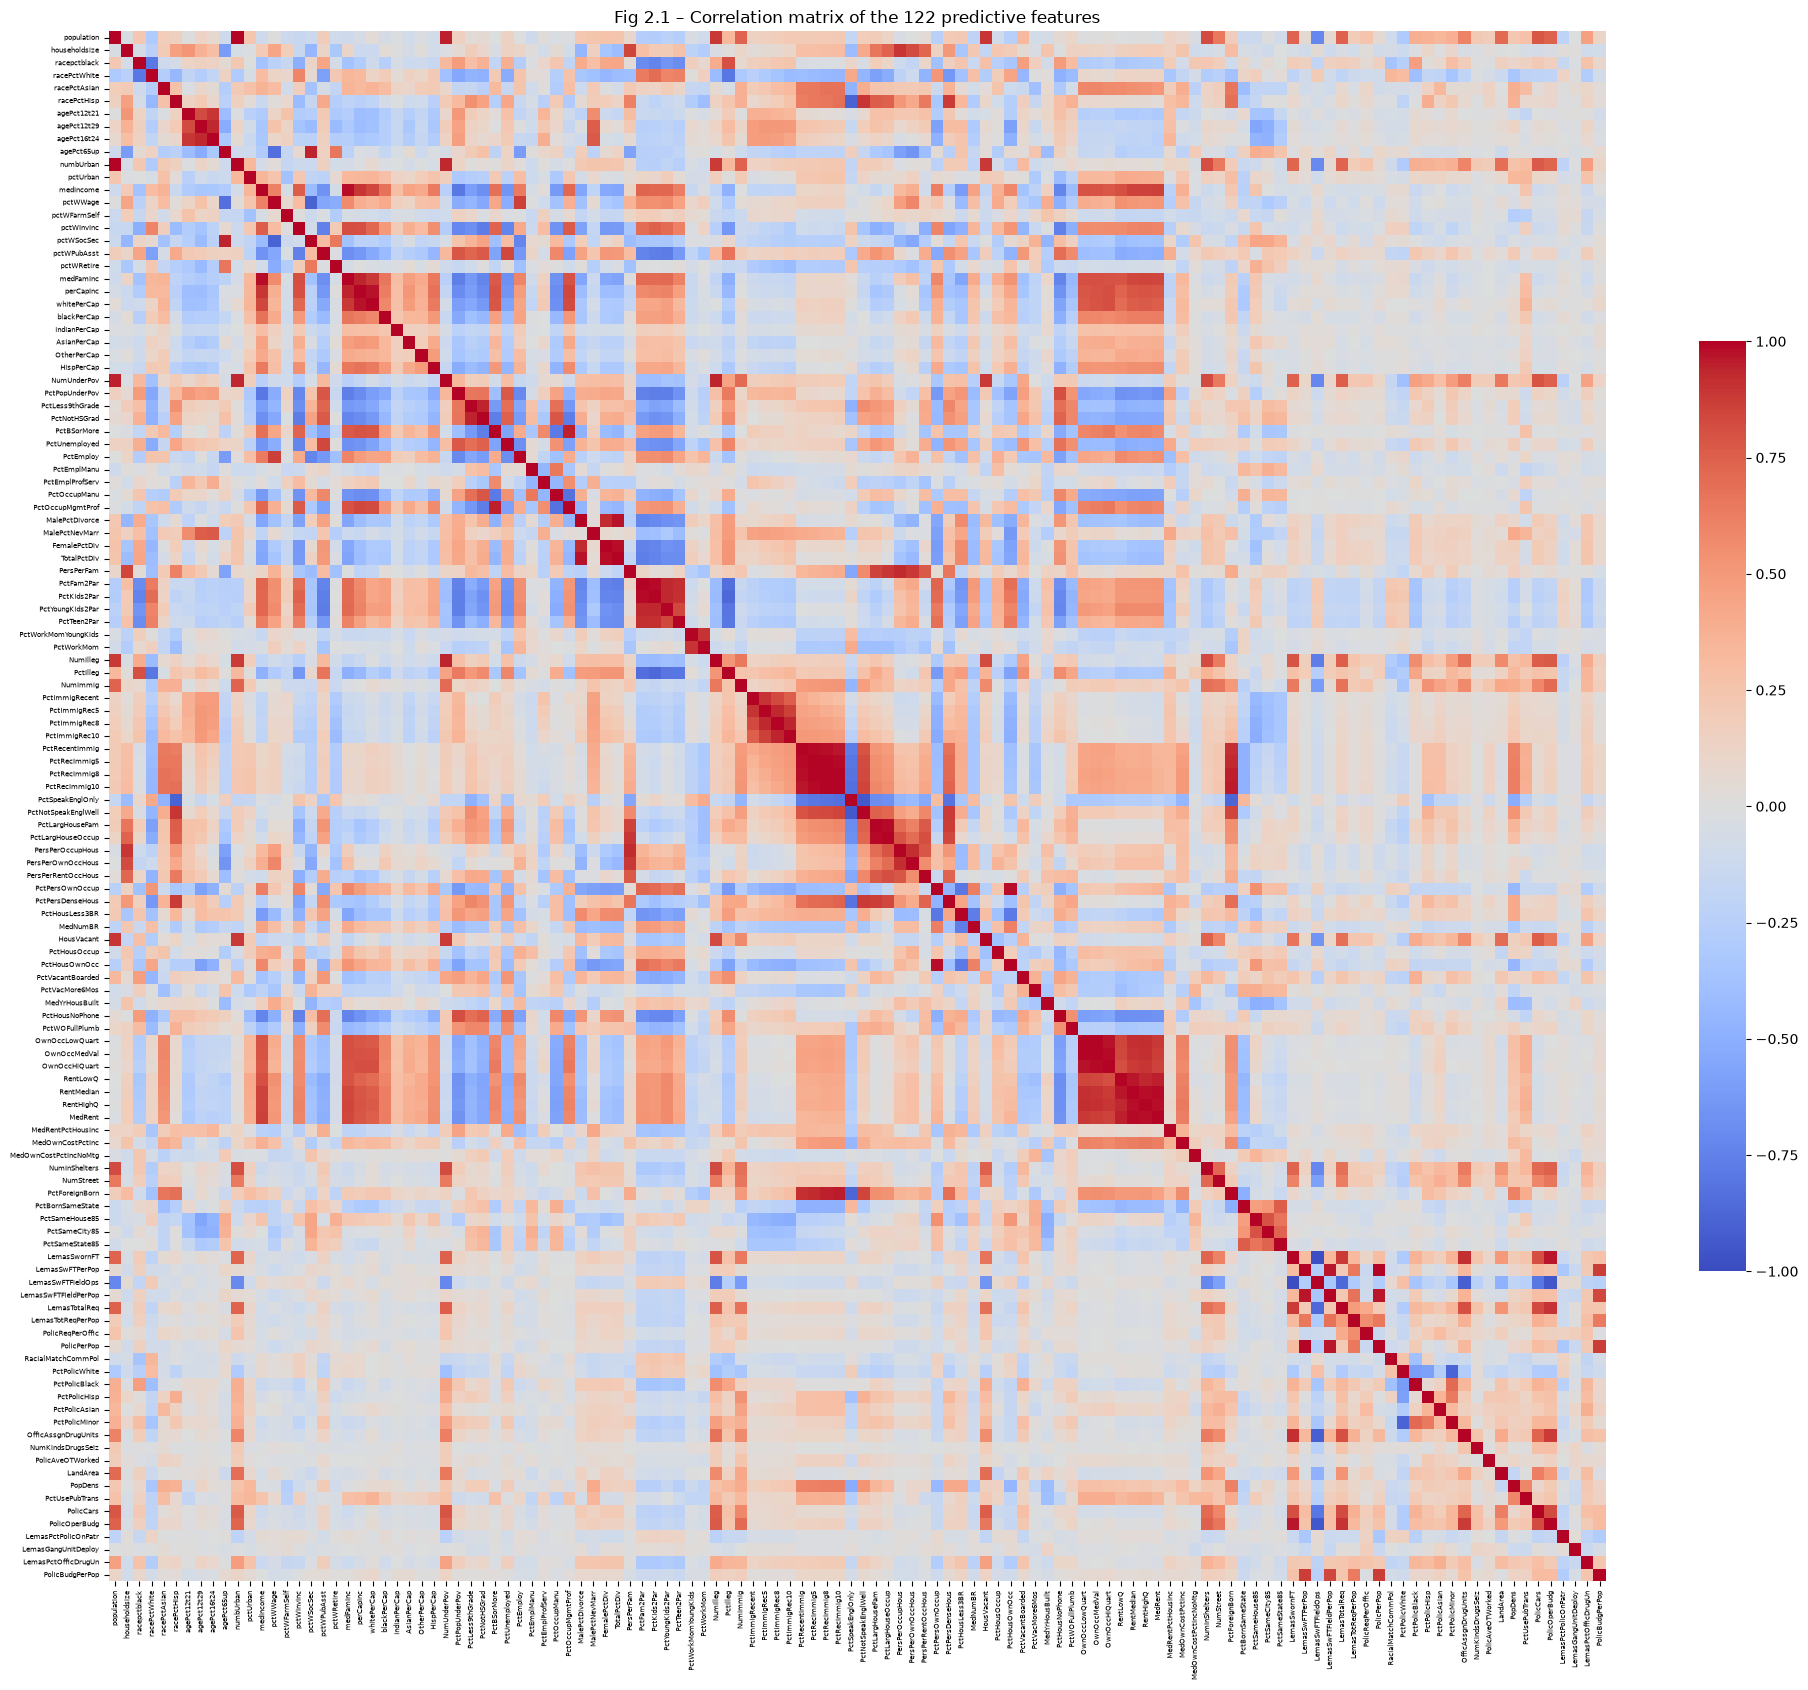

In [11]:
X_all = pd.concat([X_train, X_test])          # imputed features, whole data set
corr = X_all.corr()

plt.figure(figsize=(20, 17))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.6})
plt.xticks(fontsize=5)
plt.yticks(fontsize=5)
plt.title("Fig 2.1 – Correlation matrix of the 122 predictive features")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

$CV = s / m$, where $s$ is the sample standard deviation (ddof = 1) and $m$ is the sample mean. It is computed for each feature on the imputed whole data set.

In [12]:
cv_series = (X_all.std(ddof=1) / X_all.mean()).sort_values(ascending=False)
cv_df = cv_series.to_frame("CV")
display(cv_df)

,CV
PctPolicAsian,5.447835
NumStreet,4.407702
NumInShelters,3.485481
NumIlleg,2.994196
NumImmig,2.900497
...,...
NumKindsDrugsSeiz,0.143227
RacialMatchCommPol,0.126902
LemasPctPolicOnPatr,0.117807
PctPolicWhite,0.117726


### (e) Scatter plots and box plots for highest CV features

floor(sqrt(128)) = 11; top-CV features: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


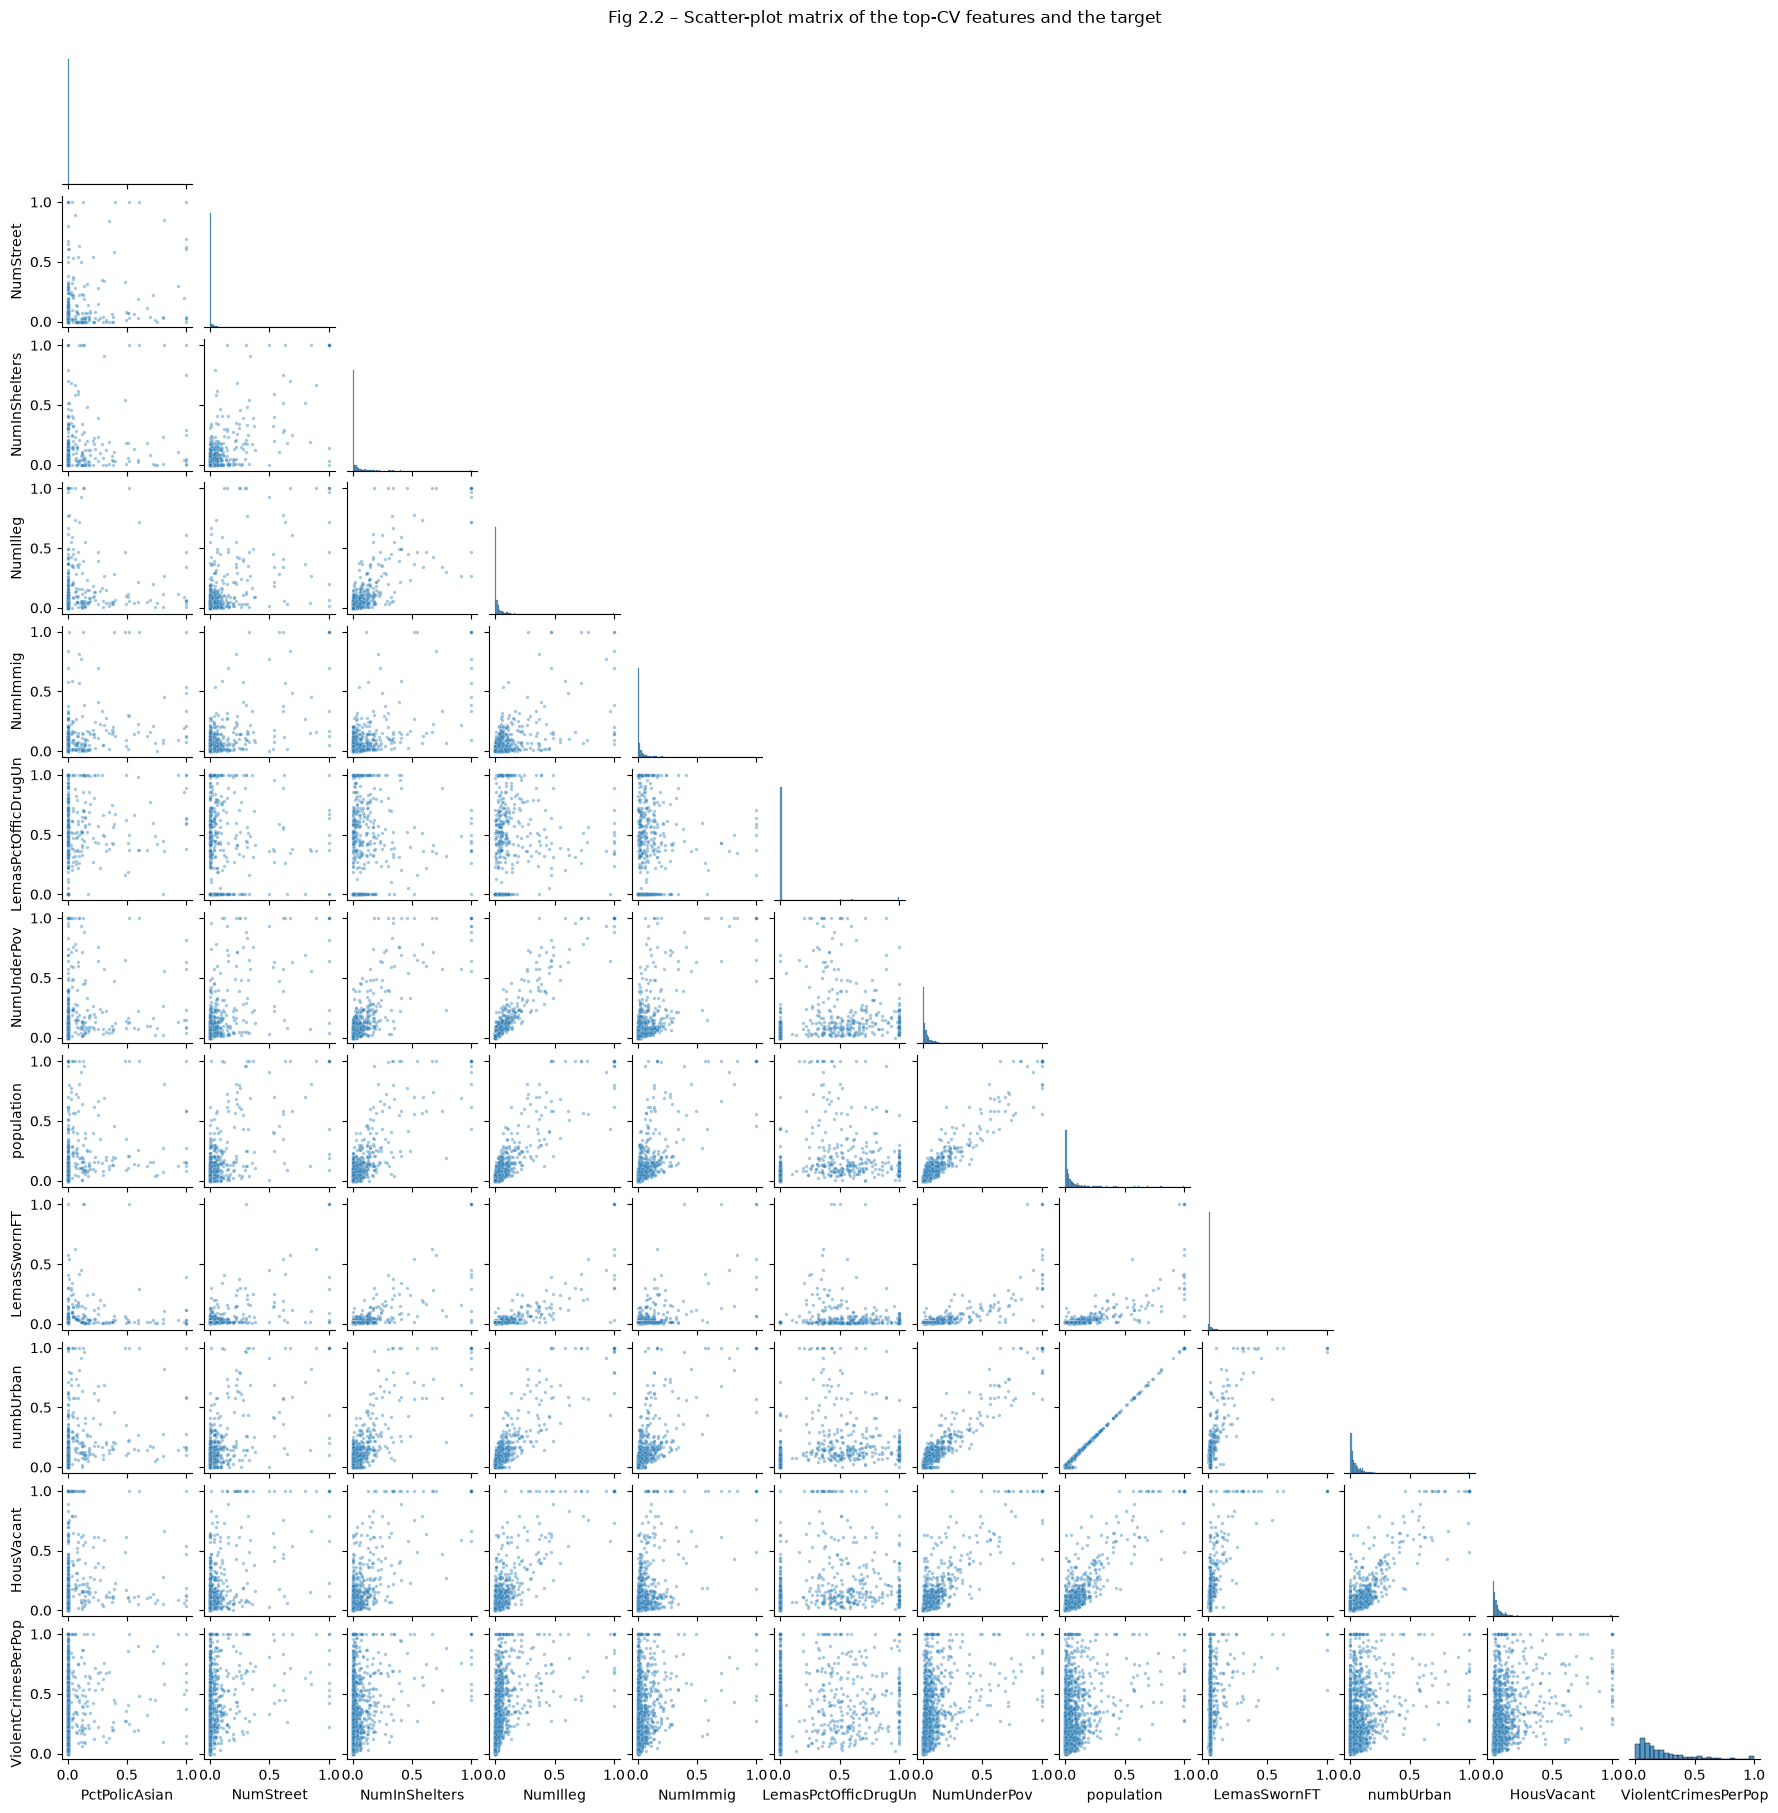

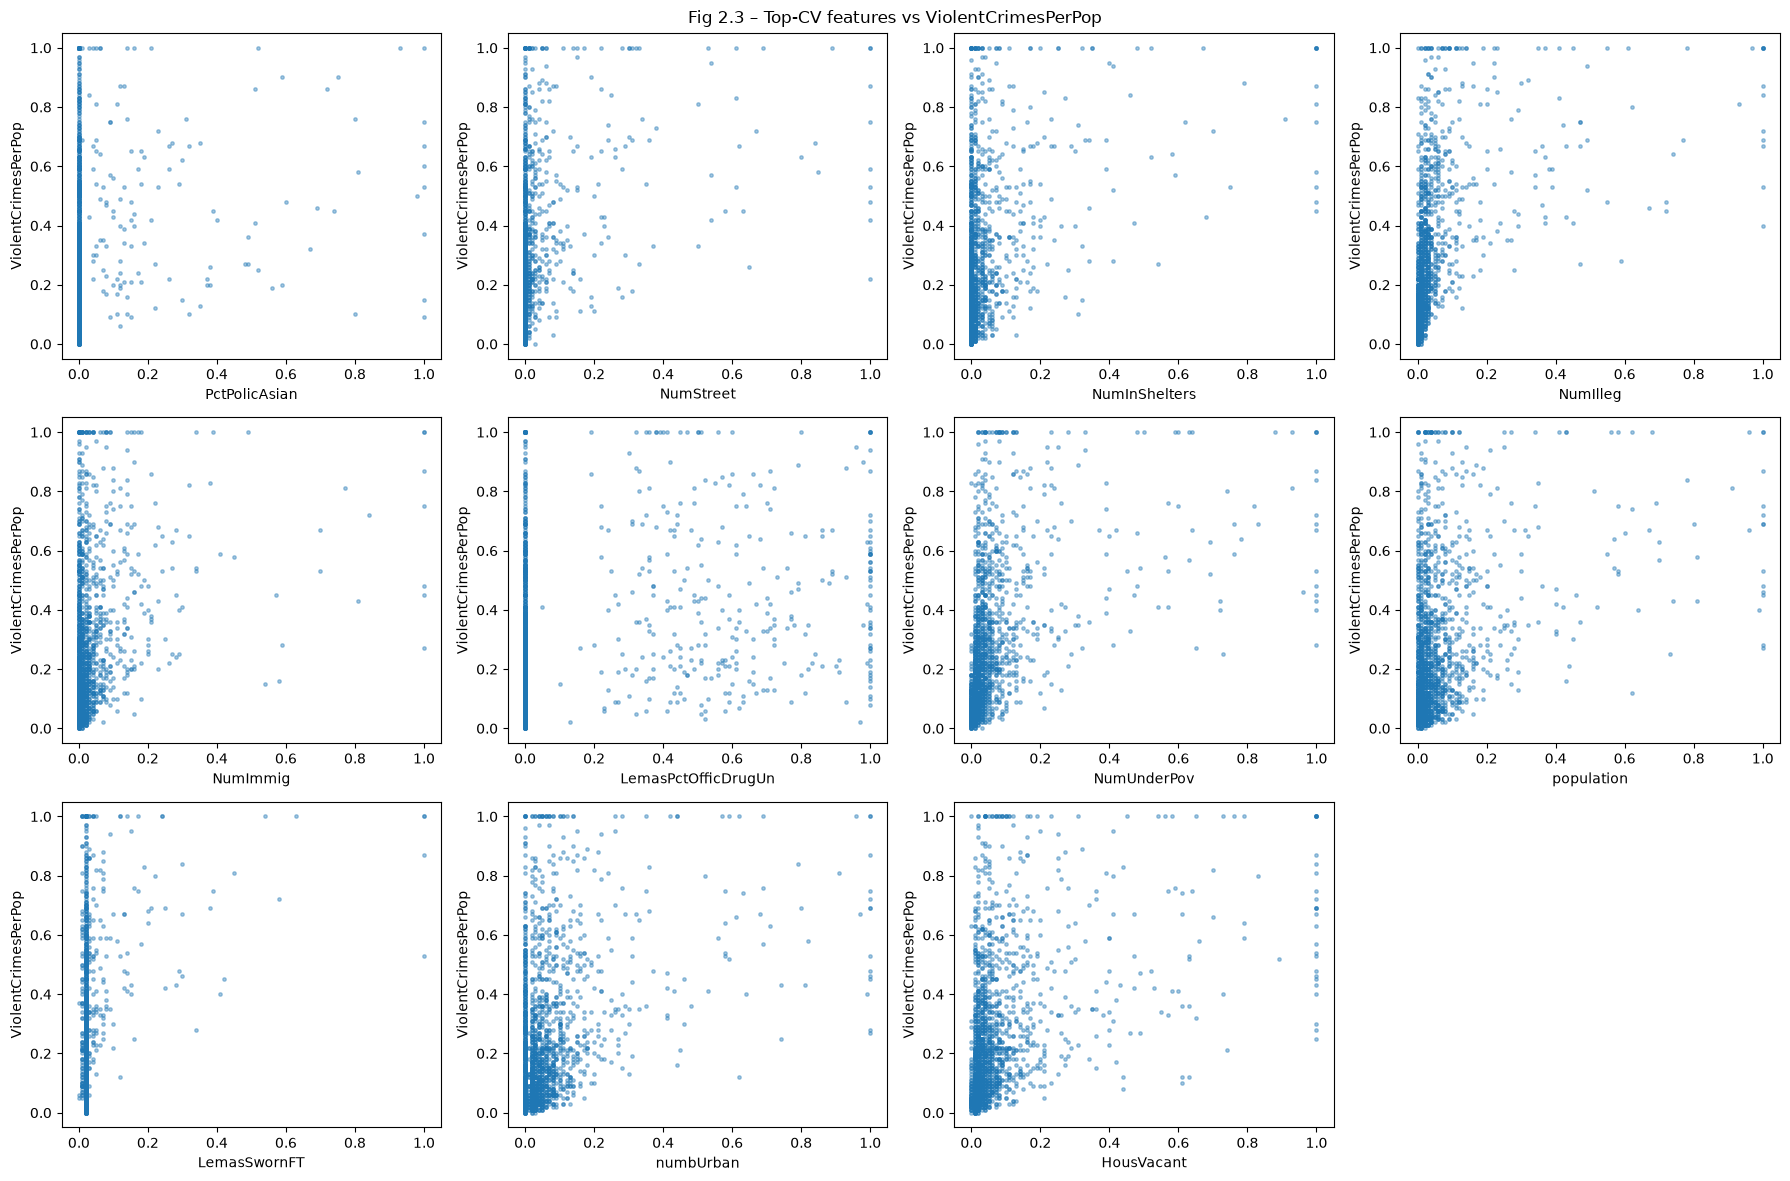

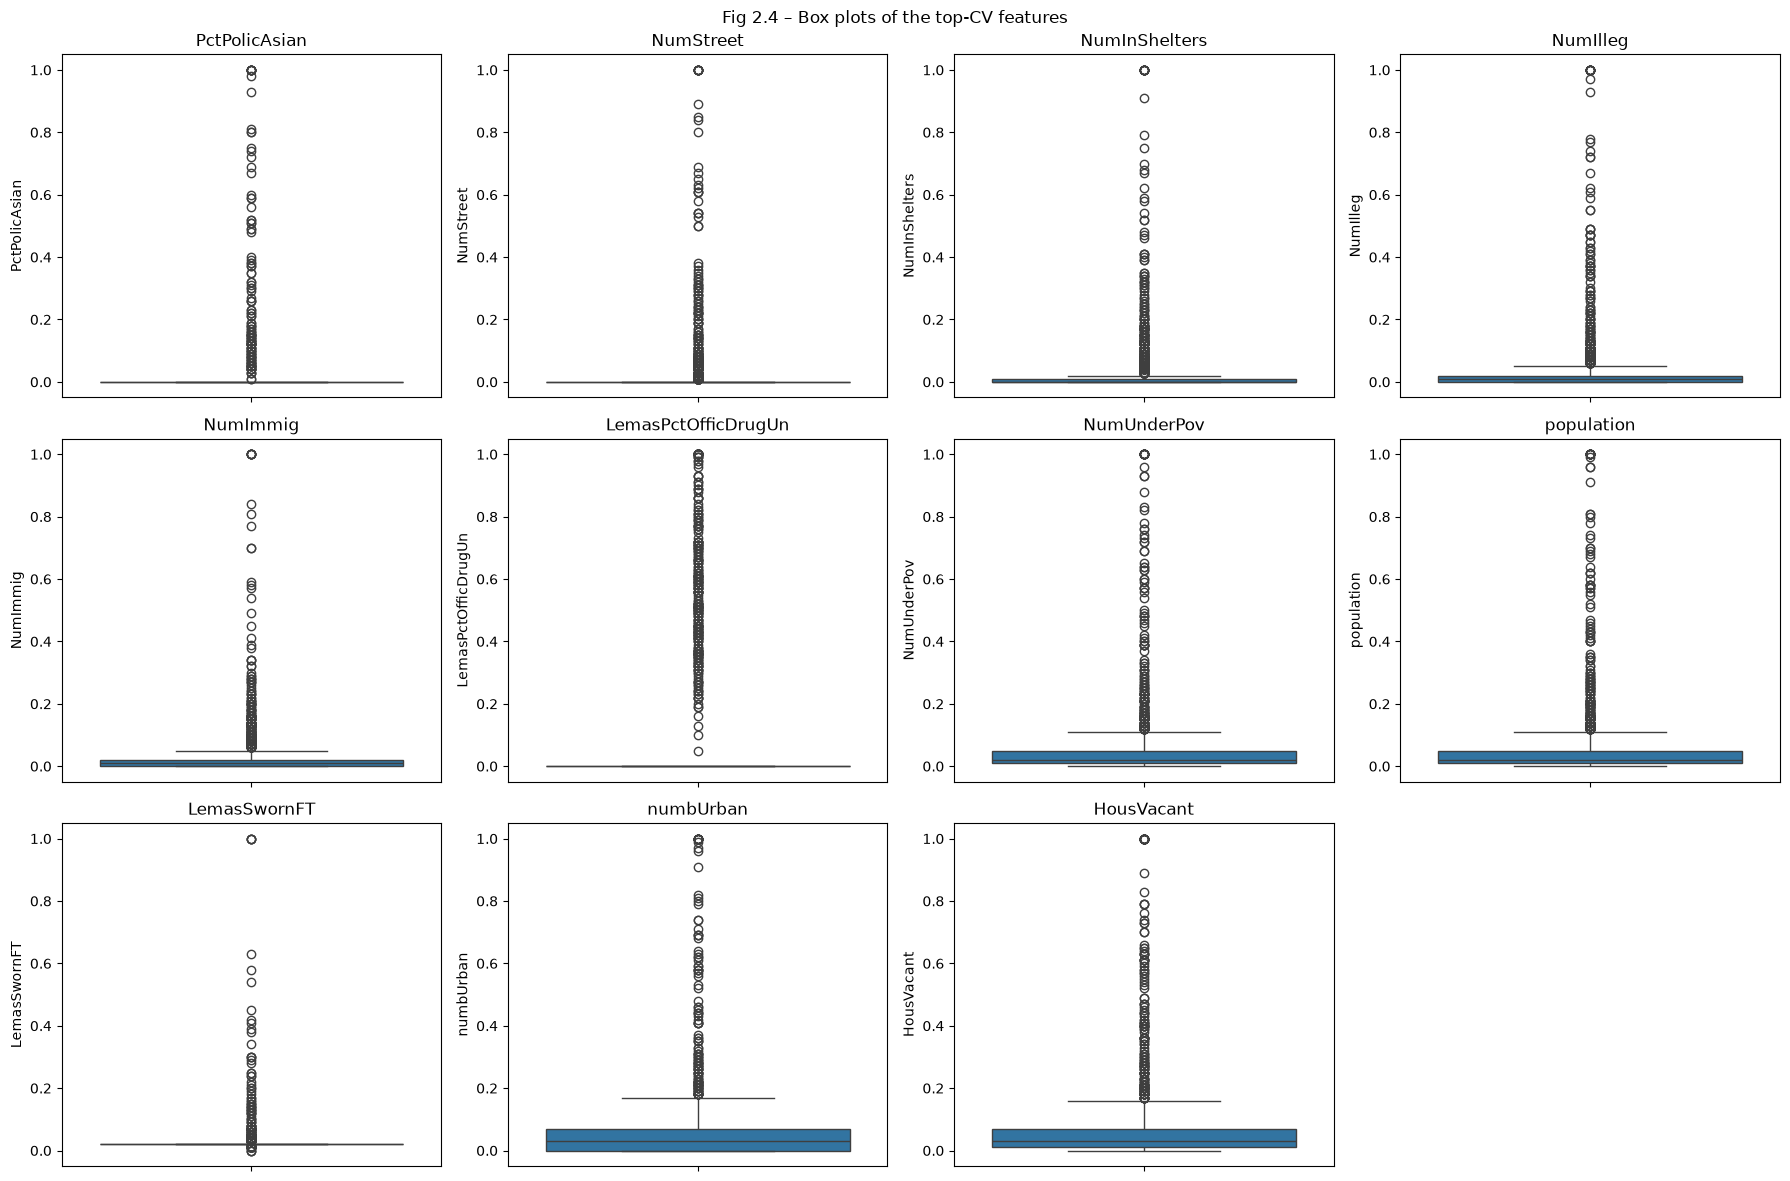

In [13]:
k = math.floor(math.sqrt(128))
top_cv = cv_series.index[:k].tolist()
print(f"floor(sqrt(128)) = {k}; top-CV features:", top_cv)

plot_df = X_all[top_cv].copy()
plot_df[TARGET] = np.concatenate([y_train, y_test])

# Scatter plot matrix
g = sns.pairplot(plot_df, corner=True, plot_kws={"s": 6, "alpha": 0.4}, height=1.5)
g.figure.suptitle("Fig 2.2 – Scatter-plot matrix of the top-CV features and the target", y=1.01)
plt.show()

# Scatter plots of each feature vs the target
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for ax, col in zip(axes.flat, top_cv):
    ax.scatter(plot_df[col], plot_df[TARGET], s=6, alpha=0.4)
    ax.set(xlabel=col, ylabel=TARGET)
axes.flat[-1].axis("off")
fig.suptitle("Fig 2.3 – Top-CV features vs ViolentCrimesPerPop")
plt.tight_layout()
plt.show()

# Box plots
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for ax, col in zip(axes.flat, top_cv):
    sns.boxplot(y=plot_df[col], ax=ax)
    ax.set_title(col)
axes.flat[-1].axis("off")
fig.suptitle("Fig 2.4 – Box plots of the top-CV features")
plt.tight_layout()
plt.show()

**Answer (e):** The $\lfloor\sqrt{128}\rfloor = 11$ features with the highest CV are:
`PctPolicAsian`, `NumStreet`, `NumInShelters`, `NumIlleg`, `NumImmig`, `LemasPctOfficDrugUn`, `NumUnderPov`, `population`, `LemasSwornFT`, `numbUrban`, `HousVacant`.

No, we cannot draw reliable conclusions about the *significance* of these features from scatter plots alone:

- **High CV ≠ predictive.** Most of these are raw *count* features (`NumStreet`, `NumInShelters`, `NumIlleg`, `NumImmig`, `NumUnderPov`, `population`, `numbUrban`, `HousVacant`). Almost all communities are near 0 and a few large cities have extreme values. That skew is what makes the CV high, and the box plots show it as a compressed box with many outliers. CV measures relative spread, not association with the target.
- **Imputation artifacts.** `PctPolicAsian`, `LemasPctOfficDrugUn` and `LemasSwornFT` are police (LEMAS) features that are 84% missing and were median-imputed. Most of their points sit on one constant value, so their scatter plots say little about the true relationship.
- **Marginal views only.** Some count features (e.g. `NumIlleg`, `NumUnderPov`) show a weak upward trend with `ViolentCrimesPerPop`. But a scatter plot shows one feature at a time, and these features are highly correlated with each other and with `population` (Fig 2.1). A feature that looks related on its own may add nothing once the others are in the model.
- Significance has to be assessed with a model, e.g. t-tests / p-values in a regression or regularized selection with the LASSO in (h).

### (f) Fit a linear model

In [14]:
def test_mse(model):
    return mean_squared_error(y_test, model.predict(X_test))

results = {}

ols = LinearRegression().fit(X_train, y_train)
results["Linear regression (OLS)"] = test_mse(ols)
print(f"Least squares test MSE: {results['Linear regression (OLS)']:.5f}")

Least squares test MSE: 0.01797


**Answer (f):** Ordinary least squares with all 122 features gives a **test MSE of 0.01797**.

### (g) Fit a ridge regression model

In [15]:
kf = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
alphas = np.logspace(-4, 4, 200)

ridge = RidgeCV(alphas=alphas, cv=kf, scoring="neg_mean_squared_error").fit(X_train, y_train)
results["Ridge"] = test_mse(ridge)
print(f"Ridge: chosen lambda = {ridge.alpha_:.4f}, test MSE = {results['Ridge']:.5f}")

Ridge: chosen lambda = 3.1806, test MSE = 0.01748


**Answer (g):** 10-fold CV chooses **λ = 3.18**, with a **test MSE of 0.01748**. This is lower than least squares (0.01797): shrinking the coefficients reduces the variance caused by the many highly correlated features.

### (h) Fit a LASSO model

In [16]:
# LASSO on the original (already normalized to [0, 1]) features
lasso = LassoCV(cv=kf, alphas=np.logspace(-6, 0, 200), max_iter=100000,
                random_state=RANDOM_STATE, n_jobs=-1)
lasso.fit(X_train, y_train)
results["LASSO"] = test_mse(lasso)
selected = pd.Series(lasso.coef_, index=feature_cols)
selected = selected[selected != 0].sort_values(key=np.abs, ascending=False)

print(f"LASSO: chosen lambda = {lasso.alpha_:.6f}, test MSE = {results['LASSO']:.5f}")
print(f"Number of selected variables: {len(selected)} / {len(feature_cols)}")
display(selected.to_frame("coefficient"))
print("Selected variables:", list(selected.index))

LASSO: chosen lambda = 0.000120, test MSE = 0.01763
Number of selected variables: 74 / 122


,coefficient
racepctblack,0.267650
agePct12t29,-0.256480
PctPersDenseHous,0.211909
PctKids2Par,-0.198225
NumStreet,0.157142
...,...
PctTeen2Par,-0.008917
PctImmigRec10,-0.003942
MedNumBR,0.002846
PctBornSameState,-0.000821


Selected variables: ['racepctblack', 'agePct12t29', 'PctPersDenseHous', 'PctKids2Par', 'NumStreet', 'MedRent', 'RentLowQ', 'PctPopUnderPov', 'PctEmploy', 'MalePctNevMarr', 'PctWorkMom', 'HousVacant', 'MalePctDivorce', 'pctWRetire', 'PctIlleg', 'pctWInvInc', 'PolicReqPerOffic', 'MedRentPctHousInc', 'NumImmig', 'NumIlleg', 'pctWWage', 'MedOwnCostPctIncNoMtg', 'FemalePctDiv', 'PctVacantBoarded', 'LemasSwFTFieldPerPop', 'PctNotSpeakEnglWell', 'agePct12t21', 'PctHousOccup', 'PctLargHouseOccup', 'NumInShelters', 'PctVacMore6Mos', 'PctHousLess3BR', 'PctPersOwnOccup', 'whitePerCap', 'pctWSocSec', 'PctForeignBorn', 'PctUsePubTrans', 'pctUrban', 'pctWPubAsst', 'PctYoungKids2Par', 'PersPerOccupHous', 'PctRecImmig10', 'LemasGangUnitDeploy', 'indianPerCap', 'NumKindsDrugsSeiz', 'LandArea', 'AsianPerCap', 'pctWFarmSelf', 'PctSameCity85', 'PctHousNoPhone', 'PctWOFullPlumb', 'OtherPerCap', 'HispPerCap', 'PctPolicAsian', 'blackPerCap', 'RacialMatchCommPol', 'PctLess9thGrade', 'PolicCars', 'PctPolicHisp

In [17]:
# LASSO on standardized features
lasso_std = Pipeline([("scaler", StandardScaler()),
                      ("lasso", LassoCV(cv=kf, alphas=np.logspace(-6, 0, 200), max_iter=100000,
                                        random_state=RANDOM_STATE, n_jobs=-1))])
lasso_std.fit(X_train, y_train)
results["LASSO (standardized)"] = test_mse(lasso_std)
coef_std = pd.Series(lasso_std.named_steps["lasso"].coef_, index=feature_cols)
selected_std = coef_std[coef_std != 0].sort_values(key=np.abs, ascending=False)

print(f"Standardized LASSO: chosen lambda = {lasso_std.named_steps['lasso'].alpha_:.6f}, "
      f"test MSE = {results['LASSO (standardized)']:.5f}")
print(f"Number of selected variables: {len(selected_std)} / {len(feature_cols)}")
display(selected_std.to_frame("coefficient"))

print("\nComparison:")
print(pd.Series({k: results[k] for k in ["LASSO", "LASSO (standardized)"]}, name="test MSE"))
print("Selected by both:", len(set(selected.index) & set(selected_std.index)))
print("Selected variables (standardized):", list(selected_std.index))

Standardized LASSO: chosen lambda = 0.000637, test MSE = 0.01772
Number of selected variables: 76 / 122


,coefficient
racepctblack,0.068019
PctPersDenseHous,0.043228
agePct12t29,-0.043049
PctKids2Par,-0.040648
RentLowQ,-0.030677
...,...
PctOccupManu,0.000722
MedNumBR,0.000696
PctImmigRec10,-0.000646
PersPerOwnOccHous,-0.000288



Comparison:
LASSO                   0.017625
LASSO (standardized)    0.017721
Name: test MSE, dtype: float64
Selected by both: 73
Selected variables (standardized): ['racepctblack', 'PctPersDenseHous', 'agePct12t29', 'PctKids2Par', 'RentLowQ', 'MedRent', 'PctPopUnderPov', 'PctEmploy', 'MalePctNevMarr', 'PctIlleg', 'PctWorkMom', 'pctWInvInc', 'MalePctDivorce', 'pctWRetire', 'HousVacant', 'NumStreet', 'pctUrban', 'MedRentPctHousInc', 'PctVacantBoarded', 'MedOwnCostPctIncNoMtg', 'FemalePctDiv', 'pctWWage', 'PctNotSpeakEnglWell', 'agePct12t21', 'PctHousOccup', 'PctLargHouseOccup', 'PctPersOwnOccup', 'NumImmig', 'PctHousLess3BR', 'PctVacMore6Mos', 'pctWSocSec', 'NumIlleg', 'PctUsePubTrans', 'PolicReqPerOffic', 'whitePerCap', 'PersPerOccupHous', 'PctRecImmig10', 'NumInShelters', 'PctForeignBorn', 'pctWPubAsst', 'PctYoungKids2Par', 'PolicCars', 'LemasSwFTFieldPerPop', 'LemasGangUnitDeploy', 'LemasTotalReq', 'AsianPerCap', 'indianPerCap', 'LandArea', 'PctWOFullPlumb', 'pctWFarmSelf', 'HispPer

**Answer (h):**

| | chosen λ | test MSE | variables selected |
|---|---|---|---|
| LASSO (original features) | 0.000120 | **0.01763** | 74 / 122 |
| LASSO (standardized features) | 0.000637 | 0.01772 | 76 / 122 |

The full lists of selected variables are printed above. The largest coefficients in both models are `racepctblack`, `agePct12t29`, `PctPersDenseHous` and `PctKids2Par`.

**Comparison.** The two models are almost identical:
- 73 variables are selected by both, and the test MSEs differ by less than 0.0001.
- The features in this data set are already normalized to [0, 1], so standardization only rescales each feature by its standard deviation. This changes the scale of λ and of the coefficients, but barely changes the fit. The LASSO penalty is not scale invariant, so the selection differs by only a few borderline variables with tiny coefficients.
- Both LASSO models drop about 40% of the features and still beat least squares (0.01797). Their accuracy is close to ridge (0.01748), with a much simpler model.

### (i) Fit a PCR model

Principal Components Regression = standardize → PCA → least squares. $M$ is chosen by 10-fold CV over $M = 1, \dots, 122$.

PCR: chosen M = 95, test MSE = 0.01830


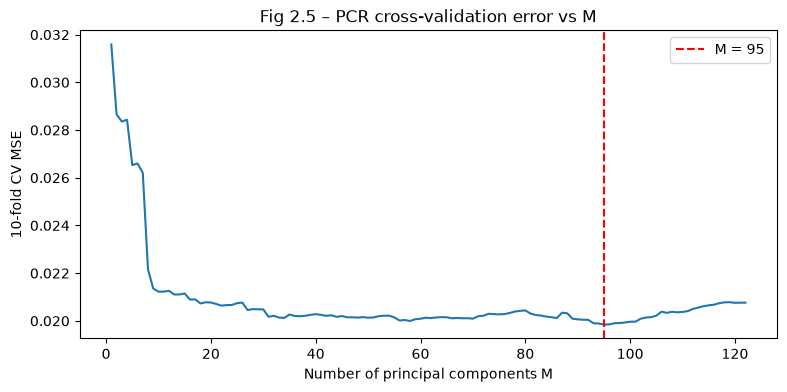

In [18]:
pcr = Pipeline([("scaler", StandardScaler()),
                ("pca", PCA(random_state=RANDOM_STATE)),
                ("reg", LinearRegression())])
param_grid = {"pca__n_components": list(range(1, len(feature_cols) + 1))}
pcr_cv = GridSearchCV(pcr, param_grid, cv=kf, scoring="neg_mean_squared_error", n_jobs=-1)
pcr_cv.fit(X_train, y_train)

best_M = pcr_cv.best_params_["pca__n_components"]
results["PCR"] = test_mse(pcr_cv.best_estimator_)
print(f"PCR: chosen M = {best_M}, test MSE = {results['PCR']:.5f}")

plt.figure(figsize=(9, 4))
plt.plot(param_grid["pca__n_components"], -pcr_cv.cv_results_["mean_test_score"])
plt.axvline(best_M, color="r", ls="--", label=f"M = {best_M}")
plt.xlabel("Number of principal components M")
plt.ylabel("10-fold CV MSE")
plt.title("Fig 2.5 – PCR cross-validation error vs M")
plt.legend()
plt.show()

**Answer (i):** 10-fold CV chooses **M = 95** principal components, with a **test MSE of 0.01830**.

Fig 2.5 shows that the CV error drops sharply over the first ~10 components and is almost flat from about M = 30 onward. The minimum at M = 95 is only marginally lower than the plateau. A model with far fewer components (around 30–60) would perform almost the same, so PCR needs many components here and gives little dimension reduction. This is consistent with the predictive information being spread across many correlated features rather than concentrated in a few leading principal components. Note that PCA is unsupervised: the leading components capture the most variance in X, not necessarily the directions most related to the crime rate.

### (j) Fit a boosting tree

XGBoost's `reg_alpha` is the L1 penalty on the leaf weights of each tree, so using it gives an L1-penalized gradient boosting tree.
The regularization term $\alpha$ is chosen by 5-fold cross-validation. The other hyperparameters are kept fixed at reasonable values.

XGBoost: chosen alpha = 1, test MSE = 0.01549


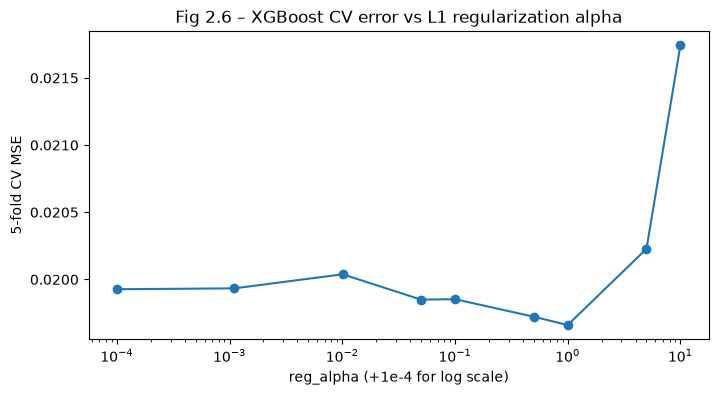

In [19]:
xgb = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=3,
                   subsample=0.8, colsample_bytree=0.8, objective="reg:squarederror",
                   random_state=RANDOM_STATE, n_jobs=-1)
alpha_grid = {"reg_alpha": [0, 1e-3, 1e-2, 0.05, 0.1, 0.5, 1, 5, 10]}
xgb_cv = GridSearchCV(xgb, alpha_grid, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                      scoring="neg_mean_squared_error")
xgb_cv.fit(X_train, y_train)

best_a = xgb_cv.best_params_["reg_alpha"]
results["XGBoost (L1-penalized)"] = test_mse(xgb_cv.best_estimator_)
print(f"XGBoost: chosen alpha = {best_a}, test MSE = {results['XGBoost (L1-penalized)']:.5f}")

plt.figure(figsize=(8, 4))
plt.semilogx(np.array(alpha_grid["reg_alpha"]) + 1e-4, -xgb_cv.cv_results_["mean_test_score"], marker="o")
plt.xlabel("reg_alpha (+1e-4 for log scale)")
plt.ylabel("5-fold CV MSE")
plt.title("Fig 2.6 – XGBoost CV error vs L1 regularization alpha")
plt.show()

**Answer (j):** 5-fold CV chooses **α (reg_alpha) = 1**, with a **test MSE of 0.01549**.

Fig 2.6 shows that the CV error is fairly flat for small α (0 to 0.1) and decreases slightly up to α = 1. It then rises sharply for α = 5 and 10, where the L1 penalty shrinks the leaf weights too much and the model underfits. A moderate L1 penalty therefore improves generalization a little, while a large one hurts.

### Summary of test errors

In [20]:
summary = pd.Series(results, name="test MSE").sort_values().to_frame()
display(summary)

,test MSE
XGBoost (L1-penalized),0.015493
Ridge,0.017478
LASSO,0.017625
LASSO (standardized),0.017721
Linear regression (OLS),0.017966
PCR,0.018296


### Summary of results



| Model | Test MSE |
|---|---|
| XGBoost (L1-penalized, α = 1) | **0.01549** |
| Ridge (λ = 3.18) | 0.01748 |
| LASSO (original features) | 0.01763 |
| LASSO (standardized) | 0.01772 |
| Least squares | 0.01797 |
| PCR (M = 95) | 0.01830 |

- The L1-penalized boosting tree has clearly the lowest test error. It can capture nonlinear effects and interactions that the linear models cannot.
- Among the linear models, the regularized ones (ridge, LASSO) improve on least squares, as expected with 122 highly correlated features.
- PCR does slightly worse than least squares. Its components are chosen without looking at the target, and it still needs 95 of them.

## References

1. UCI Machine Learning Repository – Acute Inflammations: https://archive.ics.uci.edu/ml/datasets/Acute+Inflammations
2. UCI Machine Learning Repository – Communities and Crime: https://archive.ics.uci.edu/ml/datasets/Communities+and+Crime
3. Simplifying Decision Tree Interpretability with Python & Scikit-learn (KDnuggets): https://www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html
4. scikit-learn – Post pruning decision trees with cost complexity pruning: https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html
5. scikit-learn – RidgeCV, LassoCV, PCA, Pipeline documentation: https://scikit-learn.org/stable/
6. XGBoost parameters documentation: https://xgboost.readthedocs.io/en/stable/parameter.html
7. James, Witten, Hastie, Tibshirani – *An Introduction to Statistical Learning*, Ch. 6 and Ch. 8.